# Ensemble Faster R-CNN + YOLOv10-S: resultados

Mejora de Alejandro. Combina las detecciones de los dos baselines con *Weighted Boxes Fusion* (WBF), con pesos fijos o según el tipo de imagen predicho por un clasificador entrenado con nuestras etiquetas manuales del train. Las decisiones y su justificación están en [`docs/decisiones-mejora-ensemble.md`](../docs/decisiones-mejora-ensemble.md).

No repetimos la inferencia: leemos lo que guarda

```bash
python scripts/evaluation/evaluate_ensemble.py
```

en `results/metrics/ensemble/faster_yolo_baseline/`. Los parámetros se eligieron en **validación**; test se midió una vez al final. Las figuras se guardan en `results/figures/ensemble/faster_yolo_baseline/`.

In [1]:
import json
import time

import pandas as pd
from IPython.display import display

from parasite_detection import analysis as an
from parasite_detection.ensemble import weighted_boxes_fusion
from parasite_detection.evaluation import map_on_images
from parasite_detection.paths import DEDUP_DATA, RESULTS

ENSEMBLE = RESULTS / "metrics/ensemble/faster_yolo_baseline"
figures_dir = RESULTS / "figures/ensemble/faster_yolo_baseline"
dirs = {"Faster R-CNN": RESULTS / "metrics/fasterrcnn_v2/baseline", "YOLOv10-S": RESULTS / "metrics/yolov10s/baseline",
        "Ensemble": ENSEMBLE / "ensemble_fijo"}

an.set_style()
summary = json.loads((ENSEMBLE / "summary.json").read_text(encoding="utf-8"))
coco = {s: an.load_coco(DEDUP_DATA, s) for s in ("val", "test")}
metrics = {(m, s): json.loads((d / f"{s}_metrics.json").read_text()) for m, d in dirs.items() for s in ("val", "test")}
predictions = {m: an.load_predictions(d / "test_predictions.json") for m, d in dirs.items()}
types = pd.read_csv(ENSEMBLE / "image_types.csv")

## 1. Parámetros elegidos en validación

La rejilla completa está en `val_grid.csv`. El ensemble por tipo eligió el mismo peso de YOLO dentro y fuera de microscopía, así que es idéntico al ensemble fijo: **usar el tipo de imagen no aportó nada en validación**.

In [2]:
grid = pd.read_csv(ENSEMBLE / "val_grid.csv")
best = grid.loc[grid.groupby("variante", sort=False)["val_map"].idxmax()].dropna(axis=1, how="all")
print("Elegido:", json.dumps(summary["chosen"], ensure_ascii=False))
best

Elegido: {"ensemble_fijo": {"peso_2": 0.75, "iou_thr": 0.7, "skip_thr": 0.05}, "ensemble_tipo": {"peso_2_microscopia": 0.75, "peso_2_resto": 0.75, "iou_thr": 0.7, "skip_thr": 0.05}}


,variante,iou_thr,skip_thr,peso_2,peso_2_microscopia,peso_2_resto,val_map,val_map50
0,solo fasterrcnn_v2:baseline,NaN,NaN,NaN,NaN,NaN,0.6632,0.8094
1,solo yolov10s:baseline,NaN,NaN,NaN,NaN,NaN,0.6120,0.7633
2,wbf fasterrcnn_v2:baseline,0.5,0.001,NaN,NaN,NaN,0.6632,0.8094
23,wbf yolov10s:baseline,0.7,0.001,NaN,NaN,NaN,0.6068,0.7626
61,ensemble fijo,0.7,0.050,0.75,NaN,NaN,0.6855,0.8354
84,ensemble por tipo,0.7,0.050,NaN,0.75,0.75,0.6855,0.8354


## 2. Métricas globales

El intervalo es un bootstrap pareado por imágenes de test (200 remuestreos) de mAP(ensemble) − mAP(Faster R-CNN).

Test, ensemble − Faster R-CNN: +0.0116 (IC 95 % [+0.0004, +0.0261])


,Faster R-CNN · val,YOLOv10-S · val,Ensemble · val,Faster R-CNN · test,YOLOv10-S · test,Ensemble · test
mAP@[.5:.95],0.663,0.612,0.686,0.623,0.537,0.635
mAP@0.5,0.809,0.763,0.835,0.784,0.683,0.789
mAP@0.75,0.791,0.722,0.818,0.745,0.638,0.756
AP small,0.000,0.350,0.000,0.247,0.030,0.247
AP medium,0.425,0.347,0.439,0.428,0.286,0.418
AP large,0.722,0.672,0.742,0.691,0.616,0.706
AR@100,0.766,0.751,0.786,0.749,0.699,0.767


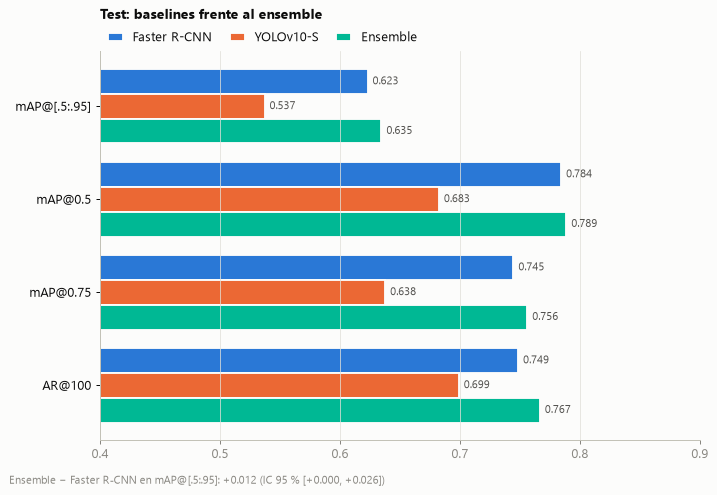

In [3]:
rows = {"mAP@[.5:.95]": "map", "mAP@0.5": "map50", "mAP@0.75": "map75", "AP small": "map_small",
        "AP medium": "map_medium", "AP large": "map_large", "AR@100": "mar100"}
table = pd.DataFrame({f"{m} · {s}": {name: metrics[(m, s)][key] for name, key in rows.items()}
                      for s in ("val", "test") for m in dirs})
ci = summary["test"]["ensemble_fijo"]["ic95_frente_a_fasterrcnn_v2:baseline"]
gain = metrics[("Ensemble", "test")]["map"] - metrics[("Faster R-CNN", "test")]["map"]
print(f"Test, ensemble − Faster R-CNN: {gain:+.4f} (IC 95 % [{ci['low']:+.4f}, {ci['high']:+.4f}])")
display(table.round(3))
shown = ["mAP@[.5:.95]", "mAP@0.5", "mAP@0.75", "AR@100"]
an.plot_grouped_bars(
    pd.DataFrame({m: [metrics[(m, "test")][rows[r]] for r in shown] for m in dirs}, index=shown),
    title="Test: baselines frente al ensemble", xlim=(0.4, 0.9),
    note=f"Ensemble − Faster R-CNN en mAP@[.5:.95]: {gain:+.3f} (IC 95 % [{ci['low']:+.3f}, {ci['high']:+.3f}])",
    path=figures_dir / "metrics_test.png");

## 3. ¿Dónde se pierde el mAP? Errores tipo TIDE

El mismo desglose que en los notebooks 04 y 05, para los tres sistemas: mAP@0.5 que recuperaría un oráculo que corrigiera cada tipo de error. Menos es mejor.

,Faster R-CNN,YOLOv10-S,Ensemble
error,,,
Clasificación,0.0875,0.1191,0.0893
Localización,0.0035,0.0090,0.0058
Duplicado,0.0000,0.0109,0.0001
Fondo,0.0490,0.0505,0.0536
No detectado,0.0196,0.0165,0.0142


,Faster R-CNN,YOLOv10-S,Ensemble
error,,,
Clasificación,721,1136,807
Localización,44,77,56
Duplicado,0,384,8
Fondo,598,829,691
No detectado,51,72,42


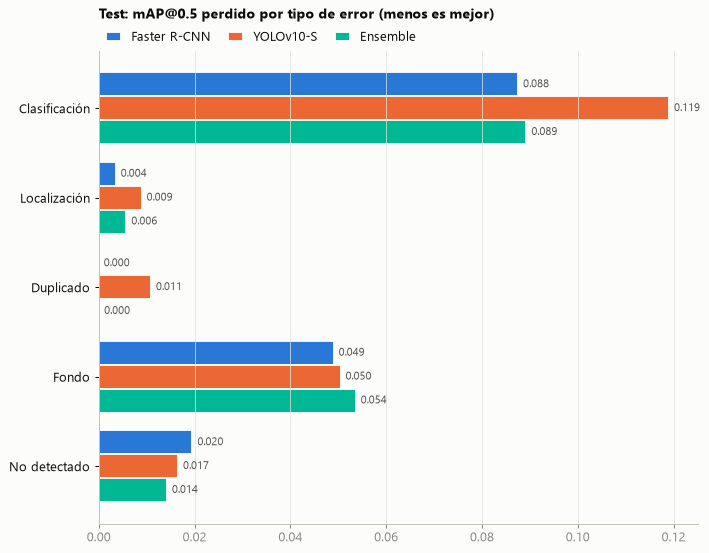

In [4]:
breakdown, counts = {}, {}
for m, p in predictions.items():
    _, t = an.error_breakdown(coco["test"], p)
    breakdown[m] = t.set_index("error")["delta_map50"]
    counts[m] = t.set_index("error")["count"]
breakdown = pd.DataFrame(breakdown)
an.plot_grouped_bars(breakdown, title="Test: mAP@0.5 perdido por tipo de error (menos es mejor)",
                     path=figures_dir / "error_breakdown_test.png")
display(breakdown.round(4))
pd.DataFrame(counts)

## 4. Por especie

,Faster R-CNN,YOLOv10-S,Ensemble,dif_ensemble_faster
Ascaris,0.733,0.667,0.747,0.014
Trichuris,0.732,0.679,0.746,0.015
Hymenolepis,0.686,0.611,0.705,0.019
Ancylostoma,0.673,0.527,0.660,-0.013
Schistosoma,0.624,0.498,0.631,0.007
Enterobius,0.547,0.486,0.570,0.023
Fasciola,0.512,0.465,0.547,0.035
Taenia,0.478,0.364,0.471,-0.007


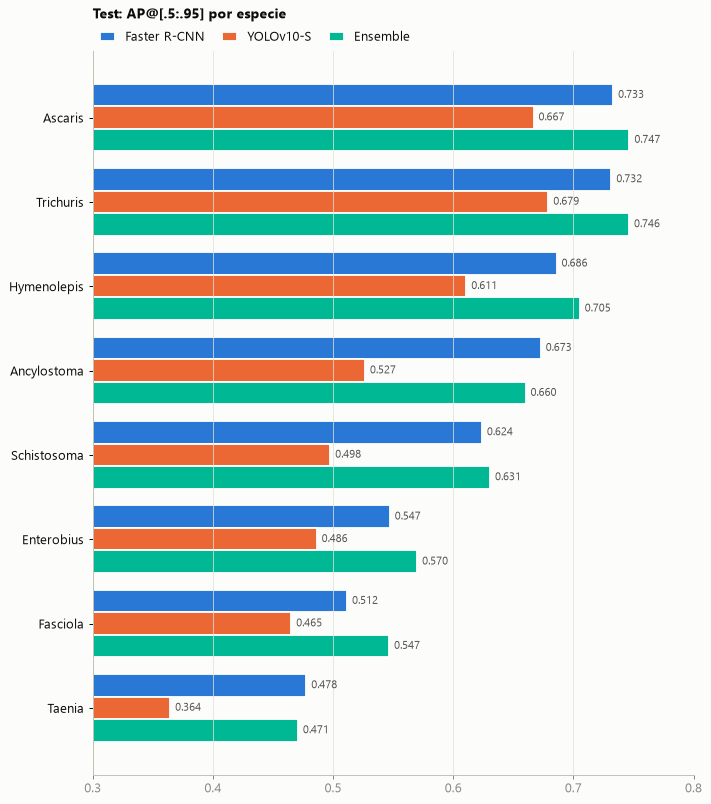

In [5]:
per_class = pd.DataFrame({m: pd.read_csv(d / "test_per_class.csv").set_index("name")["ap"] for m, d in dirs.items()})
per_class.index = [n.split()[0] for n in per_class.index]
per_class = per_class.sort_values("Ensemble", ascending=False)
an.plot_grouped_bars(per_class, title="Test: AP@[.5:.95] por especie", xlim=(0.3, 0.8),
                     path=figures_dir / "ap_per_species_test.png")
per_class.assign(dif_ensemble_faster=per_class["Ensemble"] - per_class["Faster R-CNN"]).round(3)

## 5. Por tipo de imagen (tipo predicho por el clasificador)

El tipo de cada imagen de test es el que predice el clasificador entrenado con las etiquetas manuales del train (no revisado a mano). Con solo dos grupos, como en el ensemble.

,Faster R-CNN,YOLOv10-S,Ensemble
Microscopía (321 imágenes),0.661,0.562,0.666
Resto (90 imágenes),0.508,0.442,0.537


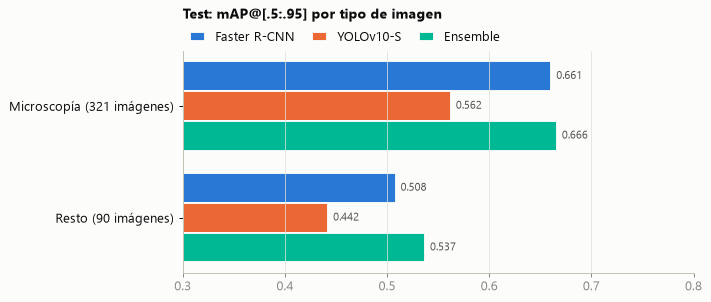

In [6]:
test_types = types[types["split"] == "test"]
by_group = {}
for group, label in (("microscopy", "Microscopía"), ("other", "Resto")):
    ids = [int(i) for i in test_types.loc[test_types["grupo"] == group, "image_id"]]
    by_group[f"{label} ({len(ids)} imágenes)"] = {m: map_on_images(coco["test"], p, ids)[0] for m, p in predictions.items()}
by_group = pd.DataFrame(by_group).T
an.plot_grouped_bars(by_group, title="Test: mAP@[.5:.95] por tipo de imagen", xlim=(0.3, 0.8),
                     path=figures_dir / "map_by_image_type_test.png")
by_group.round(3)

## 6. Latencia

La latencia de cada detector es la mediana de `benchmark_latency.py` (misma CPU, modelos alternados). La fusión se mide aquí sobre todas las imágenes de test. Si los dos detectores se ejecutan uno detrás de otro, el ensemble tarda la suma.

In [7]:
latency = json.loads((RESULTS / "metrics/latency/test_cpu.json").read_text())["models"]
chosen = summary["chosen"]["ensemble_fijo"]
start = time.perf_counter()
weighted_boxes_fusion([predictions["Faster R-CNN"], predictions["YOLOv10-S"]], [1.0, chosen["peso_2"]],
                      chosen["iou_thr"], chosen["skip_thr"])
fusion_ms = (time.perf_counter() - start) * 1000 / len(coco["test"].imgs)
faster_ms, yolo_ms = latency["fasterrcnn_v2/baseline"]["median_ms"], latency["yolov10s/baseline"]["median_ms"]
pd.DataFrame({
    "ms / imagen (mediana, CPU)": [faster_ms, yolo_ms, fusion_ms, faster_ms + yolo_ms + fusion_ms],
    "mAP@[.5:.95] test": [metrics[("Faster R-CNN", "test")]["map"], metrics[("YOLOv10-S", "test")]["map"], None,
                          metrics[("Ensemble", "test")]["map"]],
}, index=["Faster R-CNN", "YOLOv10-S", "Fusión WBF", "Ensemble (secuencial)"]).round(3)

,"ms / imagen (mediana, CPU)",mAP@[.5:.95] test
Faster R-CNN,3240.990,0.623
YOLOv10-S,265.408,0.537
Fusión WBF,0.268,NaN
Ensemble (secuencial),3506.666,0.635


## 7. Observaciones (28-11-2026)

- **El ensemble mejora a Faster R-CNN en test**: mAP@[.5:.95] 0.635 frente a 0.623 (+0.012, IC 95 % [+0.000, +0.026], probabilidad de no mejorar 0.015). Es el doble del ruido entre entrenamientos (0.006), pero el intervalo roza el cero: es una mejora real pero pequeña. En validación la ganancia era mayor (+0.022) porque ahí se eligieron los parámetros.
- **La ganancia no viene de donde esperábamos.** La hipótesis era que la fusión corregiría la especie (error de clasificación), y no lo hace: ese error queda igual (0.088 → 0.089 de mAP@0.5 perdido). El error de fondo incluso empeora un poco (0.049 → 0.054), porque YOLO añade cajas que Faster no proponía.
- **Lo que mejora es encontrar más huevos y ajustar mejor las cajas.** Los huevos no detectados bajan (0.020 → 0.014; de 51 a 42 sin ninguna detección cerca), el recall sube (AR@100 0.749 → 0.767) y la mejora es mayor con IoU exigente (mAP@0.75 +0.011) que con IoU 0.5 (mAP@0.5 +0.005): promediar las cajas de dos modelos las ajusta mejor al huevo. Coincide con la comprobación previa: YOLO encontraba un 10 % de huevos que Faster no veía.
- **Los duplicados de YOLO desaparecen** (384 → 8), aunque aplicar WBF solo a YOLO no mejoraba su mAP: lo que suma es combinar los dos modelos.
- **Por especie**, mejora en 6 de 8 (Fasciola +0.035, Enterobius +0.023) y empeora en Ancylostoma (−0.013) y Taenia (−0.007), justo las dos especies en las que YOLO es más flojo (AP 0.527 y 0.364).
- **Usar el tipo de imagen no aportó nada**: en validación el mejor peso de YOLO fue el mismo (0.75) dentro y fuera de microscopía, así que el ensemble por tipo es idéntico al fijo y el sistema final no necesita el clasificador. El indicio de la comprobación previa (P = 0.07) no se confirmó.
- **Por tipo de imagen en test** (tipo predicho, sin revisar), la ganancia es mayor fuera de microscopía (0.508 → 0.537, 90 imágenes) que en microscopía (0.661 → 0.666, 321 imágenes). Sin intervalo de confianza por grupo, es solo descriptivo.
- **Latencia**: 3.5 s por imagen en CPU ejecutando los dos detectores uno tras otro, un 8 % más que Faster solo; la fusión cuesta 0.3 ms. Frente a YOLO solo es 13 veces más lento a cambio de +0.098 de mAP.